# Lecture 3 — Line Charts: CO₂ Emissions

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the Our World in Data CO2 dataset.
# Put owid-co2-data.csv in ../data/ when running from the course repository.
try:
    raw = pd.read_csv('../data/owid-co2-data.csv')
except FileNotFoundError:
    raw = pd.read_csv('owid-co2-data.csv')

countries = [
    'United States', 'China', 'India', 'Germany', 'United Kingdom',
    'France', 'Brazil', 'Japan', 'Canada', 'Australia', 'South Korea',
    'Russia', 'South Africa', 'Mexico', 'Indonesia'
]
df = raw.loc[
    raw['country'].isin(countries) & raw['year'].between(2000, 2022),
    ['country', 'year', 'co2', 'co2_per_capita']
].dropna().rename(columns={
    'country': 'Country', 'year': 'Year',
    'co2': 'CO2_Mt', 'co2_per_capita': 'CO2_per_capita'
})
print(f'Loaded {len(df)} country-year records for {df.Country.nunique()} countries.')
print(df.head())


Loaded 345 country-year records for 15 countries.\n  Country  Year     CO2_Mt  CO2_per_capita
Australia  2000 349.897644       18.288157
Australia  2001 357.667786       18.469387
Australia  2002 362.424927       18.495451
Australia  2003 370.784424       18.708109
Australia  2004 382.004883       19.055769\n

## Task 1 — CO₂ per capita: India in context



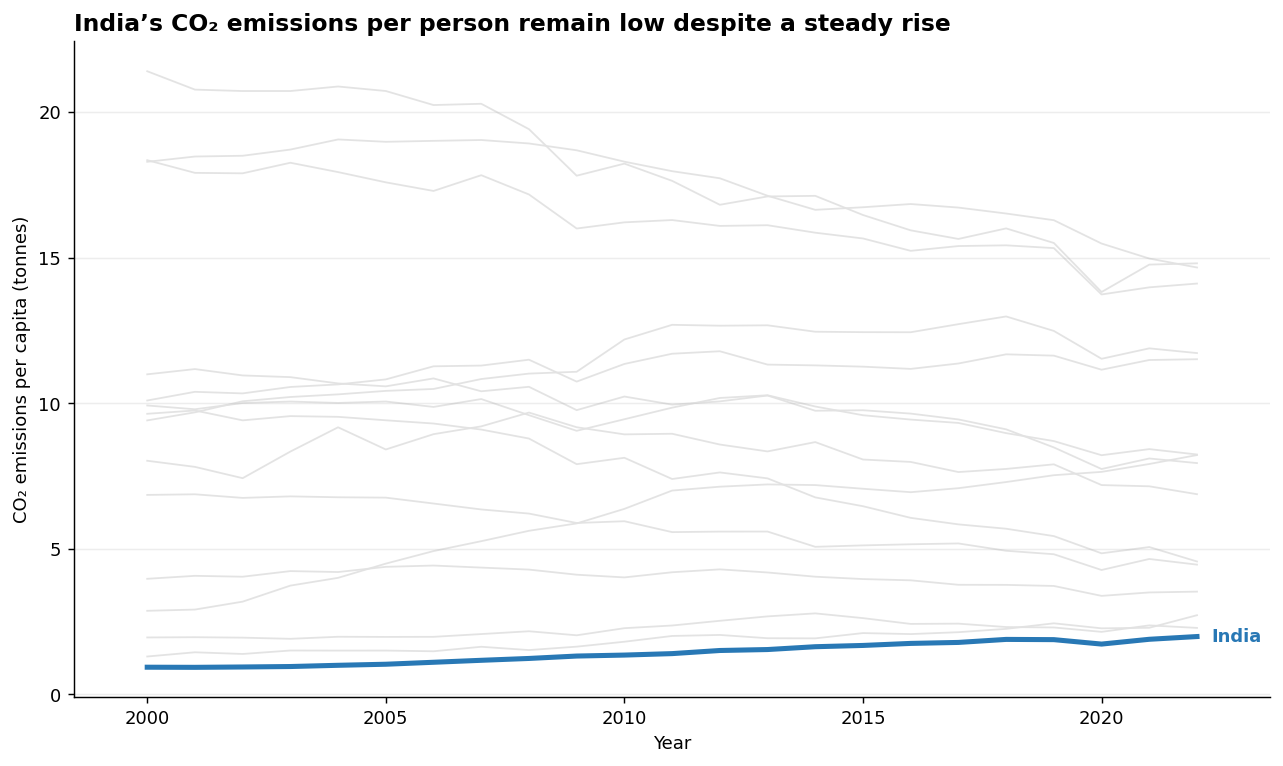

In [2]:
# All selected countries are shown; India is the only highlighted line.
fig, ax = plt.subplots(figsize=(10, 6))
for country, group in df.groupby('Country'):
    if country != 'India':
        ax.plot(group['Year'], group['CO2_per_capita'],
                color='#E2E2E2', linewidth=1.0, zorder=1)

india = df[df['Country'] == 'India'].sort_values('Year')
ax.plot(india['Year'], india['CO2_per_capita'],
        color='#2878B5', linewidth=2.8, zorder=3)
last = india.iloc[-1]
ax.annotate('India', (last['Year'], last['CO2_per_capita']),
            xytext=(8, 0), textcoords='offset points',
            va='center', fontsize=10, color='#2878B5', fontweight='bold')

ax.set_title("India's CO₂ emissions per person remain low despite a steady rise",
             loc='left', fontsize=13, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('CO₂ emissions per capita (tonnes)')
ax.grid(axis='y', alpha=.22)
ax.spines[['top', 'right']].set_visible(False)
ax.margins(x=.08)
plt.tight_layout()
plt.show()


## Task 2 — Asian countries: Indonesia's emissions trajectory

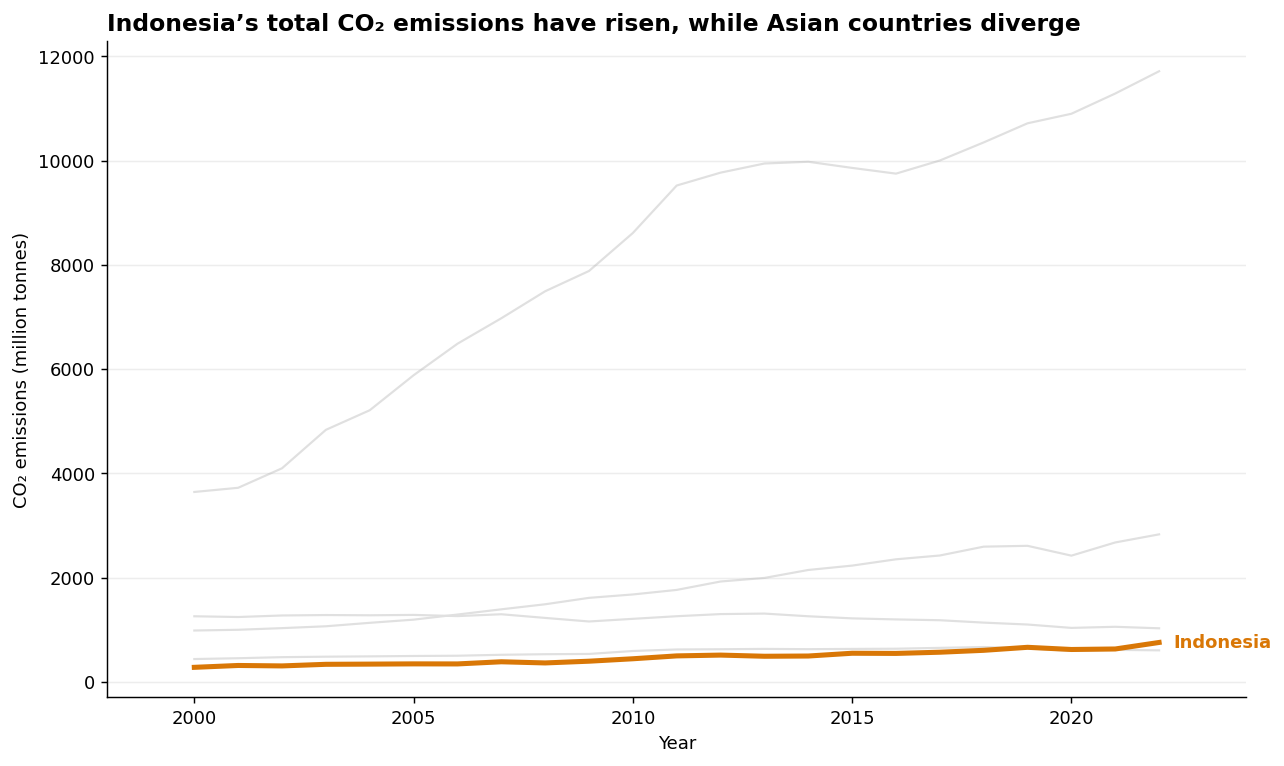

In [3]:
# Compare five Asian countries, highlighting Indonesia.
asian_countries = ['China', 'India', 'Japan', 'South Korea', 'Indonesia']
asia = df[df['Country'].isin(asian_countries)]

fig, ax = plt.subplots(figsize=(10, 6))
for country, group in asia.groupby('Country'):
    if country != 'Indonesia':
        ax.plot(group['Year'], group['CO2_Mt'],
                color='#E0E0E0', linewidth=1.2, zorder=1)

indonesia = asia[asia['Country'] == 'Indonesia'].sort_values('Year')
ax.plot(indonesia['Year'], indonesia['CO2_Mt'],
        color='#D97706', linewidth=2.8, zorder=3)
last = indonesia.iloc[-1]
ax.annotate('Indonesia', (last['Year'], last['CO2_Mt']),
            xytext=(8, 0), textcoords='offset points',
            va='center', fontsize=10, color='#D97706', fontweight='bold')

ax.set_title("Indonesia's total CO₂ emissions have risen, while Asian countries diverge",
             loc='left', fontsize=13, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('CO₂ emissions (million tonnes)')
ax.grid(axis='y', alpha=.22)
ax.spines[['top', 'right']].set_visible(False)
ax.margins(x=.09)
plt.tight_layout()
plt.show()
